# Asymmetric-Noise Sensitivity Analysis

Previous simulations assumed a uniform physical error probability across Clifford gates, idling data qubits, measurements, and resets. Because real quantum hardware exhibits distinct error rates for different operations, a circuit-level asymmetric noise model is required for realistic benchmarking.

This notebook evaluates how the logical failure probability ($P_L$) responds when varying each error mechanism independently:

- **Clifford-gate depolarisation** ($p_{\text{clifford}}$): Errors following two-qubit and single-qubit Clifford gates.
- **Data-qubit depolarisation** ($p_{\text{data}}$): Idling errors accumulated on data qubits between syndrome extraction rounds.
- **Measurement bit-flips** ($p_{\text{meas}}$): Classical readout errors during ancilla measurement.
- **Reset bit-flips** ($p_{\text{reset}}$): State-preparation errors during qubit initialisation.

### Objectives
1. Establish a common baseline noise model (`BASELINE_NOISE`).
2. Sweep one error channel at a time while holding all other parameters fixed at baseline.
3. Estimate the resulting logical failure probability via Monte Carlo sampling.
4. Compare sensitivity slopes across all four error mechanisms.
5. Identify the dominant error channel limiting logical reliability.
6. Assess whether increasing the code distance ($d$) alters the sensitivity hierarchy.

> **Note:** These results are specific to the generated rotated surface-code circuit, the chosen decoder (MWPM via PyMatching), and the selected baseline parameters. They should not be interpreted as universal hardware thresholds.


In [1]:
# Setup for rest of the notebook

# Easier way to work with files and directories
from pathlib import Path

# High-resolution timer for benchmarking execution speed
from time import perf_counter

# --- Data Handling & Numerical Operations ---
# Creates plots and figures
import matplotlib.pyplot as plt
# Provides arrays and numerical operations
import numpy as np
import pandas as pd

# --- Quantum Error Correction Simulation & Decoding ---
# Minimum-Weight Perfect Matching (MWPM) decoder for syndrome decoding
import pymatching
# Fast stabilizer circuit simulator and noise sampler
import stim

# Project directories for windows. Script exist for MacBook conversion.
PROJECT_DIR = Path(
    r"C:\Users\Karthi\Qauntum"
).resolve()

FIGURE_DIR = PROJECT_DIR / "figures"
RESULTS_DIR = PROJECT_DIR / "results"

FIGURE_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

RESULTS_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

SEED = 42

print(f"Project directory: {PROJECT_DIR}")
print("Asymmetric-noise environment ready.")

Project directory: C:\Users\Karthi\Qauntum
Asymmetric-noise environment ready.


In [2]:
# Define a noise-parameter container
BASELINE_NOISE = {
    # Depolarizing error probability after Clifford gates
    "clifford_depolarisation": 0.001,
    # Idling/data qubit depolarizing error probability per round
    "data_depolarisation": 0.0005,
    # Probability of a classical readout bit-flip during measurement
    "measurement_flip": 0.005,
    # Probability of a state preparation bit-flip upon qubit reset
    "reset_flip": 0.002,
}

# Display/verify baseline noise configuration
BASELINE_NOISE

{'clifford_depolarisation': 0.001,
 'data_depolarisation': 0.0005,
 'measurement_flip': 0.005,
 'reset_flip': 0.002}

In [3]:
# Validate noise values
# Valid noise parameter keys used for input validation and sensitivity sweep iteration
NOISE_PARAMETER_NAMES = {
    # Two-qubit and single-qubit Clifford gate depolarizing noise
    "clifford_depolarisation",
    # Idling data-qubit depolarizing noise between rounds
    "data_depolarisation",
    # Classical readout bit-flip error during measurement
    "measurement_flip",
    # State-preparation bit-flip error upon qubit reset
    "reset_flip",
}

In [4]:
# Validate a dictionary of circuit-level noise probabilities
def validate_noise_parameters(
    noise_parameters,
):

    # Extract the keys provided by the user for set comparison
    supplied_names = set(
        noise_parameters
    )

    # Ensure all required noise channels are present and no unknown keys exist
    if supplied_names != NOISE_PARAMETER_NAMES:
        missing_names = (
            NOISE_PARAMETER_NAMES
            - supplied_names
        )

        unexpected_names = (
            supplied_names
            - NOISE_PARAMETER_NAMES
        )

        raise ValueError(
            "Invalid noise-parameter names. "
            f"Missing: {sorted(missing_names)}. "
            f"Unexpected: "
            f"{sorted(unexpected_names)}."
        )

    # Verify that every error rate is a valid probability within [0.0, 1.0]
    for parameter_name, probability in (
        noise_parameters.items()
    ):
        if not 0.0 <= probability <= 1.0:
            raise ValueError(
                f"{parameter_name} must be "
                "between zero and one."
            )

In [5]:
# Verify that the baseline noise configuration has valid keys and probabilities in [0, 1]
validate_noise_parameters(
    BASELINE_NOISE
)

print(
    "Baseline noise parameters are valid."
)

Baseline noise parameters are valid.


In [6]:
# Generate a configurable rotated surface-code memory circuit using separate circuit-level noise probabilities
def create_asymmetric_surface_code_circuit(
    distance,
    rounds,
    noise_parameters,
    memory_basis="x",
):


    # Verify that noise_parameters contains valid keys and probabilities in [0.0, 1.0]
    validate_noise_parameters(
        noise_parameters
    )

    # Normalize memory basis input and confirm it is a valid logical Pauli basis ('x' or 'z')
    memory_basis = memory_basis.lower()

    if memory_basis not in {
        "x",
        "z",
    }:
        raise ValueError(
            "memory_basis must be 'x' or 'z'."
        )

    # Rotated surface codes require an odd code distance d >= 3 to define a unique logical operator
    if distance < 3 or distance % 2 == 0:
        raise ValueError(
            "distance must be an odd integer "
            "greater than or equal to three."
        )

    # Ensure at least one syndrome extraction round is simulated
    if rounds <= 0:
        raise ValueError(
            "rounds must be positive."
        )

    # Construct Stim's built-in rotated surface code task identifier (e.g., 'surface_code:rotated_memory_x')
    code_task = (
        "surface_code:rotated_memory_"
        f"{memory_basis}"
    )

    # Generate the noisy stabilizer circuit by mapping dictionary keys to Stim's error channels
    return stim.Circuit.generated(
        code_task,
        distance=distance,
        rounds=rounds,
        after_clifford_depolarization=(
            noise_parameters[
                "clifford_depolarisation"
            ]
        ),
        before_round_data_depolarization=(
            noise_parameters[
                "data_depolarisation"
            ]
        ),
        before_measure_flip_probability=(
            noise_parameters[
                "measurement_flip"
            ]
        ),
        after_reset_flip_probability=(
            noise_parameters[
                "reset_flip"
            ]
        ),
    )

In [7]:
# Simulate one noise configuration
# Generate, sample and decode one asymmetric-noise surface-code configuration
def simulate_noise_configuration(
    distance,
    noise_parameters,
    number_of_shots,
    memory_basis="x",
    seed=SEED,
):

    # Ensure a positive sample size before building circuits or allocating arrays
    if number_of_shots <= 0:
        raise ValueError(
            "number_of_shots must be positive."
        )

    # Set syndrome extraction rounds equal to code distance (standard d x d x d spacetime volume)
    rounds = distance

    # Generate the noisy rotated surface code circuit in Stim
    circuit = (
        create_asymmetric_surface_code_circuit(
            distance=distance,
            rounds=rounds,
            noise_parameters=(
                noise_parameters
            ),
            memory_basis=memory_basis,
        )
    )

    # Extract the detector error model (DEM), decomposing hyperedges into graphlike edges for MWPM
    detector_error_model = (
        circuit.detector_error_model(
            decompose_errors=True
        )
    )

    # Build the Minimum-Weight Perfect Matching (MWPM) decoder graph from the DEM
    decoder = (
        pymatching.Matching
        .from_detector_error_model(
            detector_error_model
        )
    )

    # Compile a seeded detector sampler for reproducible Monte Carlo shot generation
    sampler = (
        circuit.compile_detector_sampler(
            seed=seed
        )
    )

    # Sample syndrome detection events and actual logical observable flips, timing execution
    sampling_start = perf_counter()

    detection_events, actual_observables = (
        sampler.sample(
            shots=number_of_shots,
            separate_observables=True,
        )
    )

    sampling_end = perf_counter()

    # Warm up the decoder on a small batch so initial JIT/setup overhead doesn't skew timing
    decoder.decode_batch(
        detection_events[:10]
    )

    # Decode all sampled syndrome shots into predicted logical observable outcomes
    decoding_start = perf_counter()

    predicted_observables = (
        decoder.decode_batch(
            detection_events
        )
    )

    decoding_end = perf_counter()

    # Count shots where the decoder's logical prediction disagreed with the actual observable
    decoding_failures = np.any(
        predicted_observables
        != actual_observables,
        axis=1,
    )

    logical_failure_count = int(
        decoding_failures.sum()
    )

    logical_failure_probability = (
        logical_failure_count
        / number_of_shots
    )

    # Compute 95% confidence intervals (normal approximation when failures > 0; Rule of Three when 0)
    if logical_failure_count > 0:
        standard_error = np.sqrt(
            logical_failure_probability
            * (
                1.0
                - logical_failure_probability
            )
            / number_of_shots
        )

        confidence_lower = max(
            0.0,
            logical_failure_probability
            - 1.96 * standard_error,
        )

        confidence_upper = min(
            1.0,
            logical_failure_probability
            + 1.96 * standard_error,
        )
    else:
        standard_error = np.nan
        confidence_lower = 0.0
        confidence_upper = (
            3.0 / number_of_shots
        )

    # Summarize per-shot detector trigger counts and compute elapsed runtimes
    detection_event_counts = (
        detection_events.sum(
            axis=1
        )
    )

    sampling_seconds = (
        sampling_end - sampling_start
    )

    decoding_seconds = (
        decoding_end - decoding_start
    )

    # Return a flat dictionary of circuit metadata, noise inputs, logical error metrics, and timings
    return {
        "memory_basis": (
            memory_basis.upper()
        ),
        "distance": distance,
        "rounds": rounds,
        "shots": number_of_shots,
        **noise_parameters,
        "qubits": circuit.num_qubits,
        "detectors": circuit.num_detectors,
        "matching_edges": (
            decoder.num_edges
        ),
        "logical_failures": (
            logical_failure_count
        ),
        "logical_failure_probability": (
            logical_failure_probability
        ),
        "standard_error": (
            standard_error
        ),
        "confidence_lower_95": (
            confidence_lower
        ),
        "confidence_upper_95": (
            confidence_upper
        ),
        "mean_detection_events": float(
            detection_event_counts.mean()
        ),
        "median_detection_events": float(
            np.median(
                detection_event_counts
            )
        ),
        "p95_detection_events": float(
            np.percentile(
                detection_event_counts,
                95,
            )
        ),
        "sampling_seconds": (
            sampling_seconds
        ),
        "decoding_seconds": (
            decoding_seconds
        ),
        "decoder_microseconds_per_shot": (
            1e6
            * decoding_seconds
            / number_of_shots
        ),
    }

In [9]:
# Baseline constants
BASELINE_DISTANCE = 7
BASELINE_SHOTS = 200_000

In [10]:
# Run the reference Monte Carlo simulation using the baseline code distance and noise profile
baseline_result = (
    simulate_noise_configuration(
        distance=BASELINE_DISTANCE,
        noise_parameters=(
            BASELINE_NOISE
        ),
        number_of_shots=(
            BASELINE_SHOTS
        ),
        memory_basis="x",
        seed=SEED,
    )
)

# Convert the output dictionary to a pandas Series for clean tabular display in the notebook
pd.Series(
    baseline_result
)

memory_basis                            X
distance                                7
rounds                                  7
shots                              200000
clifford_depolarisation             0.001
data_depolarisation                0.0005
measurement_flip                    0.005
reset_flip                          0.002
qubits                                118
detectors                             336
matching_edges                       1558
logical_failures                       10
logical_failure_probability       0.00005
standard_error                   0.000016
confidence_lower_95              0.000019
confidence_upper_95              0.000081
mean_detection_events            8.475875
median_detection_events               8.0
p95_detection_events                 16.0
sampling_seconds                 0.061175
decoding_seconds                   0.3103
decoder_microseconds_per_shot    1.551501
dtype: object

In [11]:
# Check the output
# Sanity-check that the estimated logical failure rate is a valid probability in [0, 1]
assert (
    0.0
    <= baseline_result[
        "logical_failure_probability"
    ]
    <= 1.0
)

# Confirm that the average number of triggered detectors per shot is non-negative
assert (
    baseline_result[
        "mean_detection_events"
    ]
    >= 0.0
)

# Print confirmation once all baseline validation checks pass
print(
    "Baseline asymmetric-noise simulation "
    "completed successfully."
)

Baseline asymmetric-noise simulation completed successfully.


In [12]:
# Scaling factors applied one-at-a-time to each baseline error rate during sensitivity sweeps
# (0.0 isolates noiseless channel behavior; 1.0 reproduces the baseline point; >1.0 tests elevated noise)
NOISE_MULTIPLIERS = np.array(
    [
        0.0,
        0.25,
        0.5,
        1.0,
        1.5,
        2.0,
        3.0,
        5.0,
    ],
    dtype=float,
)

# Display array in notebook output to verify sweep grid
NOISE_MULTIPLIERS

array([0.  , 0.25, 0.5 , 1.  , 1.5 , 2.  , 3.  , 5.  ])

In [13]:
# Modified model
# Copy the baseline model and multiply one selected noise probability
def create_modified_noise_model(
    baseline_noise,
    varied_parameter,
    multiplier,
):

    # Verify that the baseline noise dictionary has valid keys and probabilities in [0.0, 1.0]
    validate_noise_parameters(
        baseline_noise
    )

    # Confirm that the target parameter is one of the recognized noise channels
    if varied_parameter not in (
        NOISE_PARAMETER_NAMES
    ):
        raise ValueError(
            f"Unknown noise parameter: "
            f"{varied_parameter}"
        )

    # Ensure the scaling factor does not produce a negative error probability
    if multiplier < 0.0:
        raise ValueError(
            "multiplier cannot be negative."
        )

    # Create a shallow copy so the original baseline dictionary remains unmodified
    modified_noise = dict(
        baseline_noise
    )

    # Scale the selected channel's error rate and verify it remains a valid probability <= 1.0
    varied_probability = (
        baseline_noise[
            varied_parameter
        ]
        * multiplier
    )

    if varied_probability > 1.0:
        raise ValueError(
            "Modified probability exceeds one."
        )

    # Update the single varied parameter while holding all other error channels at baseline
    modified_noise[
        varied_parameter
    ] = varied_probability

    return modified_noise

In [14]:
# Sanity-check create_modified_noise_model by doubling measurement_flip while holding other channels fixed
test_noise_model = (
    create_modified_noise_model(
        baseline_noise=BASELINE_NOISE,
        varied_parameter=(
            "measurement_flip"
        ),
        multiplier=2.0,
    )
)

# Display dictionary to verify only 'measurement_flip' changed (0.005 -> 0.010)
test_noise_model

{'clifford_depolarisation': 0.001,
 'data_depolarisation': 0.0005,
 'measurement_flip': 0.01,
 'reset_flip': 0.002}

In [15]:
# Verify that the varied channel ('measurement_flip') scaled to 2x its baseline value (0.005 -> 0.010)
assert np.isclose(
    test_noise_model[
        "measurement_flip"
    ],
    0.010,
)

# Confirm that an unvaried channel ('clifford_depolarisation') remained untouched at baseline
assert np.isclose(
    test_noise_model[
        "clifford_depolarisation"
    ],
    BASELINE_NOISE[
        "clifford_depolarisation"
    ],
)

# Print confirmation once the noise-scaling unit test passes
print(
    "Noise-model modification passed."
)

Noise-model modification passed.


In [16]:
# Define the sensitivity experiment
# Simulation settings for the single-distance sensitivity sweep
SENSITIVITY_DISTANCE = 7
SENSITIVITY_SHOTS = 200_000

# Ordered list of circuit-level noise channels to vary independently one-at-a-time
VARIED_PARAMETERS = [
    "clifford_depolarisation",
    "data_depolarisation",
    "measurement_flip",
    "reset_flip",
]

In [17]:
# Run the sweep
# Accumulate simulation result dictionaries across all one-at-a-time parameter sweeps
sensitivity_results = []

# Track overall sweep progress across all (parameter, multiplier) combinations
configuration_index = 0
total_configurations = (
    len(VARIED_PARAMETERS)
    * len(NOISE_MULTIPLIERS)
)

# Iterate through each noise channel independently, sweeping across all scaling multipliers
for varied_parameter in (
    VARIED_PARAMETERS
):
    for multiplier in (
        NOISE_MULTIPLIERS
    ):
        configuration_index += 1

        # Build the modified noise profile with only `varied_parameter` scaled
        noise_model = (
            create_modified_noise_model(
                baseline_noise=(
                    BASELINE_NOISE
                ),
                varied_parameter=(
                    varied_parameter
                ),
                multiplier=(
                    multiplier
                ),
            )
        )

        # Extract the scaled physical error probability for logging and tabular output
        varied_probability = (
            noise_model[
                varied_parameter
            ]
        )

        # Log progress and current parameter settings before running Monte Carlo sampling
        print(
            f"Running "
            f"{configuration_index}/"
            f"{total_configurations} | "
            f"parameter={varied_parameter} | "
            f"multiplier={multiplier:.2f} | "
            f"probability="
            f"{varied_probability:.4%}"
        )

        # Run the QEC simulation using a distinct deterministic seed per configuration
        result = (
            simulate_noise_configuration(
                distance=(
                    SENSITIVITY_DISTANCE
                ),
                noise_parameters=(
                    noise_model
                ),
                number_of_shots=(
                    SENSITIVITY_SHOTS
                ),
                memory_basis="x",
                seed=(
                    SEED
                    + configuration_index
                ),
            )
        )

        # Tag the output record with sweep metadata for grouping and plotting later
        result[
            "varied_parameter"
        ] = varied_parameter

        result[
            "multiplier"
        ] = multiplier

        result[
            "varied_probability"
        ] = varied_probability

        sensitivity_results.append(
            result
        )

        # Log summary logical failure rate and syndrome activity immediately upon completion
        print(
            f"  logical="
            f"{result['logical_failure_probability']:.6e} | "
            f"failures="
            f"{result['logical_failures']:,} | "
            f"mean events="
            f"{result['mean_detection_events']:.3f}"
        )

Running 1/32 | parameter=clifford_depolarisation | multiplier=0.00 | probability=0.0000%
  logical=5.000000e-06 | failures=1 | mean events=5.255
Running 2/32 | parameter=clifford_depolarisation | multiplier=0.25 | probability=0.0250%
  logical=1.500000e-05 | failures=3 | mean events=6.056
Running 3/32 | parameter=clifford_depolarisation | multiplier=0.50 | probability=0.0500%
  logical=1.000000e-05 | failures=2 | mean events=6.857
Running 4/32 | parameter=clifford_depolarisation | multiplier=1.00 | probability=0.1000%
  logical=5.000000e-05 | failures=10 | mean events=8.436
Running 5/32 | parameter=clifford_depolarisation | multiplier=1.50 | probability=0.1500%
  logical=9.500000e-05 | failures=19 | mean events=10.048
Running 6/32 | parameter=clifford_depolarisation | multiplier=2.00 | probability=0.2000%
  logical=1.900000e-04 | failures=38 | mean events=11.611
Running 7/32 | parameter=clifford_depolarisation | multiplier=3.00 | probability=0.3000%
  logical=7.350000e-04 | failures=14

In [18]:
# Convert the list of simulation result dictionaries into a structured DataFrame
sensitivity_df = pd.DataFrame(
    sensitivity_results
)

# Display key sweep parameters alongside logical error rates and syndrome activity for inspection
sensitivity_df[
    [
        "varied_parameter",
        "multiplier",
        "varied_probability",
        "logical_failures",
        "logical_failure_probability",
        "mean_detection_events",
    ]
]

,varied_parameter,multiplier,varied_probability,logical_failures,logical_failure_probability,mean_detection_events
0,clifford_depolarisation,0.00,0.000000,1,0.000005,5.254610
1,clifford_depolarisation,0.25,0.000250,3,0.000015,6.055905
2,clifford_depolarisation,0.50,0.000500,2,0.000010,6.856925
3,clifford_depolarisation,1.00,0.001000,10,0.000050,8.436080
4,clifford_depolarisation,1.50,0.001500,19,0.000095,10.047700
5,clifford_depolarisation,2.00,0.002000,38,0.000190,11.611315
6,clifford_depolarisation,3.00,0.003000,147,0.000735,14.670870
7,clifford_depolarisation,5.00,0.005000,942,0.004710,20.633185
8,data_depolarisation,0.00,0.000000,3,0.000015,8.115055
9,data_depolarisation,0.25,0.000125,5,0.000025,8.196040


In [19]:
# Extract the one-times baseline points
# Filter for multiplier == 1.0 rows across all sweeps (each reproduces the baseline noise profile)
# But the Monte Carlo estimates differ because of the different random seeds
baseline_sweep_rows = (
    sensitivity_df[
        np.isclose(
            sensitivity_df[
                "multiplier"
            ],
            1.0,
        )
    ]
)

# Compare baseline logical failure estimates and standard errors across independent random seeds
baseline_sweep_rows[
    [
        "varied_parameter",
        "logical_failure_probability",
        "standard_error",
    ]
]

,varied_parameter,logical_failure_probability,standard_error
3,clifford_depolarisation,0.000050,0.000016
11,data_depolarisation,0.000035,0.000013
19,measurement_flip,0.000050,0.000016
27,reset_flip,0.000035,0.000013


In [20]:
# Average the logical failure probability across the repeated baseline runs (multiplier == 1.0) to establish a low-variance reference point for relative sensitivity comparisons
mean_baseline_logical_rate = (
    baseline_sweep_rows[
        "logical_failure_probability"
    ].mean()
)

# Display the pooled baseline logical failure rate in scientific notation
print(
    "Mean repeated baseline logical rate: "
    f"{mean_baseline_logical_rate:.6e}"
)

Mean repeated baseline logical rate: 4.250000e-05


In [21]:
# Calculate relative change
# Compute the multiplicative sensitivity factor (>1.0 indicates worse logical error than baseline)
sensitivity_df[
    "logical_rate_relative_to_baseline"
] = (
    sensitivity_df[
        "logical_failure_probability"
    ]
    / mean_baseline_logical_rate
)

# Compute the signed additive shift in logical failure probability relative to the baseline mean
sensitivity_df[
    "absolute_logical_rate_change"
] = (
    sensitivity_df[
        "logical_failure_probability"
    ]
    - mean_baseline_logical_rate
)

In [23]:
# Plot logical failure against multiplier
# Display labels for plotting legends and summary tables
PARAMETER_LABELS = {
    "clifford_depolarisation": (
        "Clifford-gate depolarisation"
    ),
    "data_depolarisation": (
        "Data depolarisation"
    ),
    "measurement_flip": (
        "Measurement flip"
    ),
    "reset_flip": (
        "Reset flip"
    ),
}

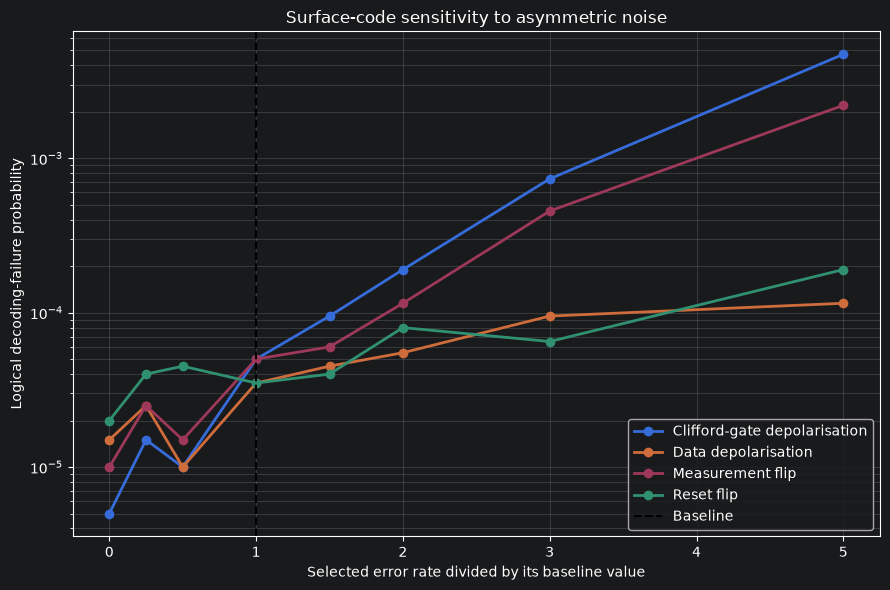

In [24]:
# Create a single-panel figure comparing logical failure scaling across noise channels
figure, axis = plt.subplots(
    figsize=(9, 6)
)

# Plot logical failure probability vs. noise multiplier independently for each error channel
for parameter_name in (
    VARIED_PARAMETERS
):
    subset = sensitivity_df[
        sensitivity_df[
            "varied_parameter"
        ] == parameter_name
    ].sort_values(
        "multiplier"
    )

    axis.plot(
        subset["multiplier"],
        subset[
            "logical_failure_probability"
        ],
        marker="o",
        linewidth=2,
        label=(
            PARAMETER_LABELS[
                parameter_name
            ]
        ),
    )

# Add a vertical reference line at multiplier = 1.0 marking the shared baseline operating point
axis.axvline(
    1.0,
    color="black",
    linestyle="--",
    linewidth=1.5,
    label="Baseline",
)

# Use a logarithmic y-axis to resolve multi-decade changes in logical failure probability
axis.set_yscale("log")

# Configure axis labels, plot title, gridlines, and legend
axis.set_xlabel(
    "Selected error rate divided by "
    "its baseline value"
)

axis.set_ylabel(
    "Logical decoding-failure probability"
)

axis.set_title(
    "Surface-code sensitivity to asymmetric noise"
)

axis.grid(
    True,
    which="both",
    alpha=0.3,
)

axis.legend()

# Adjust padding, export high-resolution PNG to disk, and display inline
figure.tight_layout()

sensitivity_curve_path = (
    FIGURE_DIR
    / "asymmetric_noise_sensitivity.png"
)

figure.savefig(
    sensitivity_curve_path,
    dpi=200,
    bbox_inches="tight",
)

plt.show()

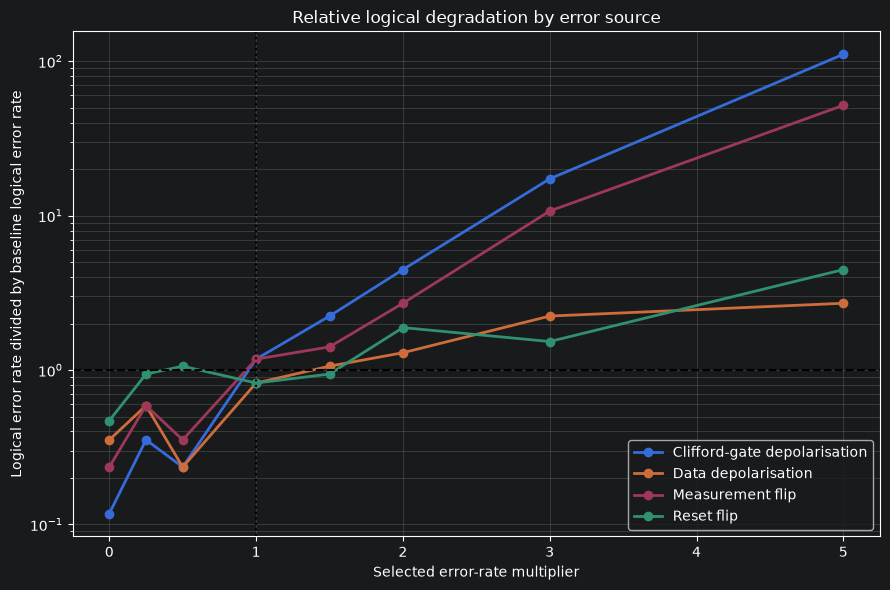

In [25]:
# Plot relative logical degradation
# Create a figure comparing normalized logical error degradation relative to baseline
figure, axis = plt.subplots(
    figsize=(9, 6)
)

# Plot normalized logical failure ratio vs. noise multiplier for each independent error source
for parameter_name in (
    VARIED_PARAMETERS
):
    subset = sensitivity_df[
        sensitivity_df[
            "varied_parameter"
        ] == parameter_name
    ].sort_values(
        "multiplier"
    )

    axis.plot(
        subset["multiplier"],
        subset[
            "logical_rate_relative_to_baseline"
        ],
        marker="o",
        linewidth=2,
        label=(
            PARAMETER_LABELS[
                parameter_name
            ]
        ),
    )

# Add horizontal and vertical reference lines intersecting at the baseline point (1.0, 1.0)
axis.axhline(
    1.0,
    color="black",
    linestyle="--",
    linewidth=1.5,
)

axis.axvline(
    1.0,
    color="black",
    linestyle=":",
    linewidth=1.5,
)

# Use a logarithmic y-axis to capture order-of-magnitude relative degradation
axis.set_yscale("log")

# Configure axis labels, plot title, gridlines, and legend
axis.set_xlabel(
    "Selected error-rate multiplier"
)

axis.set_ylabel(
    "Logical error rate divided by "
    "baseline logical error rate"
)

axis.set_title(
    "Relative logical degradation by error source"
)

axis.grid(
    True,
    which="both",
    alpha=0.3,
)

axis.legend()

# Adjust padding, save high-resolution PNG to disk, and display inline
figure.tight_layout()

relative_sensitivity_path = (
    FIGURE_DIR
    / "asymmetric_noise_relative_sensitivity.png"
)

figure.savefig(
    relative_sensitivity_path,
    dpi=200,
    bbox_inches="tight",
)

plt.show()

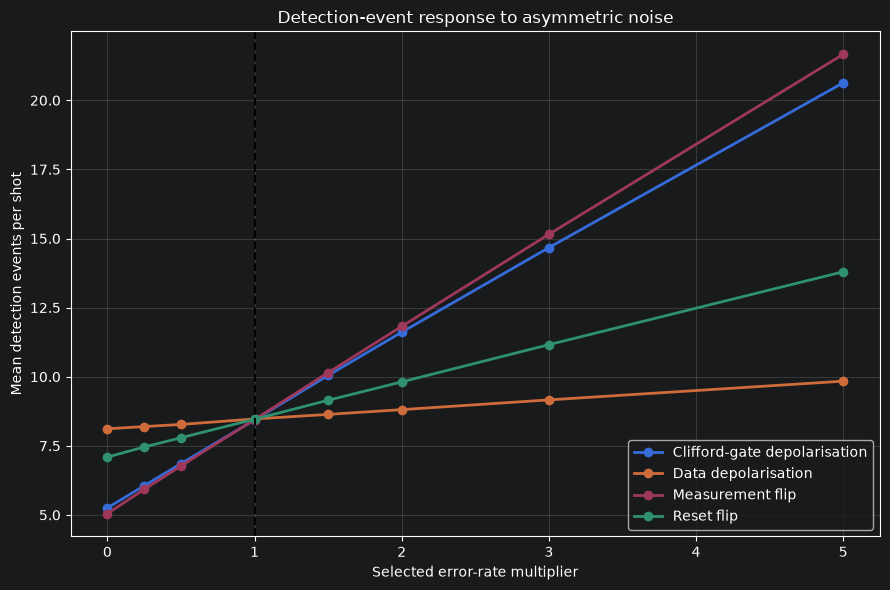

In [26]:
# Compare event generation
# Create a figure tracking syndrome detector activity across varying noise multipliers
figure, axis = plt.subplots(
    figsize=(9, 6)
)

# Plot mean detection events per shot vs. noise multiplier for each independent error source
for parameter_name in (
    VARIED_PARAMETERS
):
    subset = sensitivity_df[
        sensitivity_df[
            "varied_parameter"
        ] == parameter_name
    ].sort_values(
        "multiplier"
    )

    axis.plot(
        subset["multiplier"],
        subset[
            "mean_detection_events"
        ],
        marker="o",
        linewidth=2,
        label=(
            PARAMETER_LABELS[
                parameter_name
            ]
        ),
    )

# Add a vertical dashed line at multiplier = 1.0 marking the shared baseline operating point
axis.axvline(
    1.0,
    color="black",
    linestyle="--",
    linewidth=1.5,
)

# Configure axis labels, plot title, gridlines, and legend (linear y-axis for raw event counts)
axis.set_xlabel(
    "Selected error-rate multiplier"
)

axis.set_ylabel(
    "Mean detection events per shot"
)

axis.set_title(
    "Detection-event response to asymmetric noise"
)

axis.grid(
    True,
    alpha=0.3,
)

axis.legend()

figure.tight_layout()

event_sensitivity_path = (
    FIGURE_DIR
    / "asymmetric_noise_detection_events.png"
)

figure.savefig(
    event_sensitivity_path,
    dpi=200,
    bbox_inches="tight",
)

plt.show()

In [27]:
# Estimate logarithmic sensitivity
# Accumulate local elasticity (log-log slope) metrics around the baseline operating point
local_sensitivity_results = []

for parameter_name in (
    VARIED_PARAMETERS
):
    subset = sensitivity_df[
        sensitivity_df[
            "varied_parameter"
        ] == parameter_name
    ]

    # Extract bounding bracket rows at 0.5x and 2.0x the baseline error probability
    lower_row = subset[
        np.isclose(
            subset["multiplier"],
            0.5,
        )
    ].iloc[0]

    upper_row = subset[
        np.isclose(
            subset["multiplier"],
            2.0,
        )
    ].iloc[0]

    # Retrieve logical failure probabilities and corresponding physical error rates at both bounds
    lower_logical_rate = lower_row[
        "logical_failure_probability"
    ]

    upper_logical_rate = upper_row[
        "logical_failure_probability"
    ]

    lower_physical_rate = lower_row[
        "varied_probability"
    ]

    upper_physical_rate = upper_row[
        "varied_probability"
    ]

    # Compute logarithmic sensitivity (power-law exponent d(log P_L) / d(log p)) across [0.5x, 2.0x]
    if (
        lower_logical_rate > 0.0
        and upper_logical_rate > 0.0
        and lower_physical_rate > 0.0
        and upper_physical_rate > 0.0
    ):
        logarithmic_sensitivity = (
            np.log(
                upper_logical_rate
                / lower_logical_rate
            )
            / np.log(
                upper_physical_rate
                / lower_physical_rate
            )
        )
    else:
        logarithmic_sensitivity = np.nan

    # Store summary metrics for ranking error channels by local sensitivity
    local_sensitivity_results.append(
        {
            "parameter": (
                parameter_name
            ),
            "parameter_label": (
                PARAMETER_LABELS[
                    parameter_name
                ]
            ),
            "logical_rate_at_half_baseline": (
                lower_logical_rate
            ),
            "logical_rate_at_double_baseline": (
                upper_logical_rate
            ),
            "logarithmic_sensitivity": (
                logarithmic_sensitivity
            ),
        }
    )

# Convert to DataFrame and rank error mechanisms from most sensitive to least sensitive
local_sensitivity_df = pd.DataFrame(
    local_sensitivity_results
).sort_values(
    "logarithmic_sensitivity",
    ascending=False,
)

local_sensitivity_df

,parameter,parameter_label,logical_rate_at_half_baseline,logical_rate_at_double_baseline,logarithmic_sensitivity
0,clifford_depolarisation,Clifford-gate depolarisation,0.000010,0.000190,2.123964
2,measurement_flip,Measurement flip,0.000015,0.000115,1.469300
1,data_depolarisation,Data depolarisation,0.000010,0.000055,1.229716
3,reset_flip,Reset flip,0.000045,0.000080,0.415037


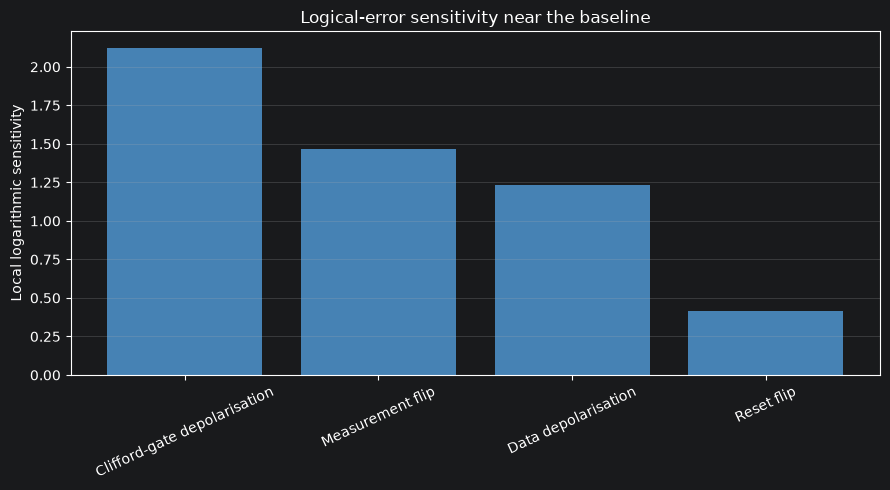

In [28]:
# Plot the sensitivity ranking
# Create a bar chart ranking error mechanisms by local logarithmic sensitivity
figure, axis = plt.subplots(
    figsize=(9, 5)
)

# Plot sorted logarithmic sensitivity values (power-law exponents) for each error source
axis.bar(
    local_sensitivity_df[
        "parameter_label"
    ],
    local_sensitivity_df[
        "logarithmic_sensitivity"
    ],
    color="steelblue",
)

# Configure y-axis label, plot title, x-tick rotation, and horizontal gridlines
axis.set_ylabel(
    "Local logarithmic sensitivity"
)

axis.set_title(
    "Logical-error sensitivity near the baseline"
)

axis.tick_params(
    axis="x",
    rotation=25,
)

axis.grid(
    axis="y",
    alpha=0.3,
)

figure.tight_layout()

sensitivity_ranking_path = (
    FIGURE_DIR
    / "asymmetric_noise_sensitivity_ranking.png"
)

figure.savefig(
    sensitivity_ranking_path,
    dpi=200,
    bbox_inches="tight",
)

plt.show()

In [29]:
# Define candidate noise profiles to test whether sensitivity ordering changes with code distance
DISTANCE_COMPARISON_MODELS = {
    "Baseline": dict(
        BASELINE_NOISE
    ),
    # Reference asymmetric noise configuration (all multipliers = 1.0)
    "Double measurement error": (
        create_modified_noise_model(
            BASELINE_NOISE,
            "measurement_flip",
            2.0,
        )
    ),
    # Elevated readout noise (measurement_flip = 0.010, others at baseline)
    "Double Clifford error": (
        create_modified_noise_model(
            BASELINE_NOISE,
            "clifford_depolarisation",
            2.0,
        )
    ),  # Elevated two-qubit/single-qubit gate noise (clifford_depolarisation = 0.002, others at baseline)
}

# Odd rotated surface-code distances evaluated for error-suppression scaling
DISTANCE_COMPARISON_VALUES = [
    3,
    5,
    7,
    9,
]

# Fixed Monte Carlo sample count per (noise model, code distance) pair to avoid excessive computation
DISTANCE_COMPARISON_SHOTS = 200_000

In [30]:
# Accumulate simulation results across all (noise profile, code distance) pairs
distance_sensitivity_results = []

# Track configuration count to assign distinct deterministic RNG seeds
configuration_index = 0

# Sweep each noise profile across increasing rotated surface-code distances (d = 3, 5, 7, 9)
for model_name, noise_model in (
    DISTANCE_COMPARISON_MODELS.items()
):
    for distance in (
        DISTANCE_COMPARISON_VALUES
    ):
        configuration_index += 1

        # Log current noise model and code distance before running Monte Carlo sampling
        print(
            f"Model={model_name} | "
            f"distance={distance}"
        )

        # Simulate rotated surface-code memory with an offset seed block (+10,000) to avoid overlap
        result = (
            simulate_noise_configuration(
                distance=distance,
                noise_parameters=noise_model,
                number_of_shots=(
                    DISTANCE_COMPARISON_SHOTS
                ),
                memory_basis="x",
                seed=(
                    SEED
                    + 10_000
                    + configuration_index
                ),
            )
        )

        # Label output record with the human-readable noise model name for grouping and plotting
        result["noise_model_name"] = (
            model_name
        )

        distance_sensitivity_results.append(
            result
        )

        # Log estimated logical failure probability and raw failure count upon completion
        print(
            f"  logical="
            f"{result['logical_failure_probability']:.6e} | "
            f"failures="
            f"{result['logical_failures']:,}"
        )

Model=Baseline | distance=3
  logical=1.570000e-03 | failures=314
Model=Baseline | distance=5
  logical=2.400000e-04 | failures=48
Model=Baseline | distance=7
  logical=3.000000e-05 | failures=6
Model=Baseline | distance=9
  logical=5.000000e-06 | failures=1
Model=Double measurement error | distance=3
  logical=3.360000e-03 | failures=672
Model=Double measurement error | distance=5
  logical=8.400000e-04 | failures=168
Model=Double measurement error | distance=7
  logical=1.150000e-04 | failures=23
Model=Double measurement error | distance=9
  logical=4.500000e-05 | failures=9
Model=Double Clifford error | distance=3
  logical=3.275000e-03 | failures=655
Model=Double Clifford error | distance=5
  logical=9.600000e-04 | failures=192
Model=Double Clifford error | distance=7
  logical=2.000000e-04 | failures=40
Model=Double Clifford error | distance=9
  logical=4.000000e-05 | failures=8


In [31]:
# Convert the multi-distance simulation result dictionaries into a structured DataFrame
distance_sensitivity_df = pd.DataFrame(
    distance_sensitivity_results
)

# Display logical failure scaling and syndrome activity across code distances for each noise profile
distance_sensitivity_df[
    [
        "noise_model_name",
        "distance",
        "logical_failures",
        "logical_failure_probability",
        "mean_detection_events",
    ]
]

,noise_model_name,distance,logical_failures,logical_failure_probability,mean_detection_events
0,Baseline,3,314,0.001570,0.536805
1,Baseline,5,48,0.000240,2.903165
2,Baseline,7,6,0.000030,8.454680
3,Baseline,9,1,0.000005,18.512415
4,Double measurement error,3,672,0.003360,0.786310
5,Double measurement error,5,168,0.000840,4.131350
6,Double measurement error,7,23,0.000115,11.816715
7,Double measurement error,9,9,0.000045,25.657735
8,Double Clifford error,3,655,0.003275,0.690515
9,Double Clifford error,5,192,0.000960,3.927840


In [32]:
# Plot distance dependence
# Use upper bounds when no failures occur
# Substitute the 95% confidence upper bound (Rule of Three: 3 / N) when zero logical failures occur so log-scale plots display a finite upper limit instead of dropping zero-valued points
distance_sensitivity_df[
    "logical_rate_for_plot"
] = np.where(
    distance_sensitivity_df[
        "logical_failures"
    ] > 0,
    distance_sensitivity_df[
        "logical_failure_probability"
    ],
    3.0
    / distance_sensitivity_df[
        "shots"
    ],
)

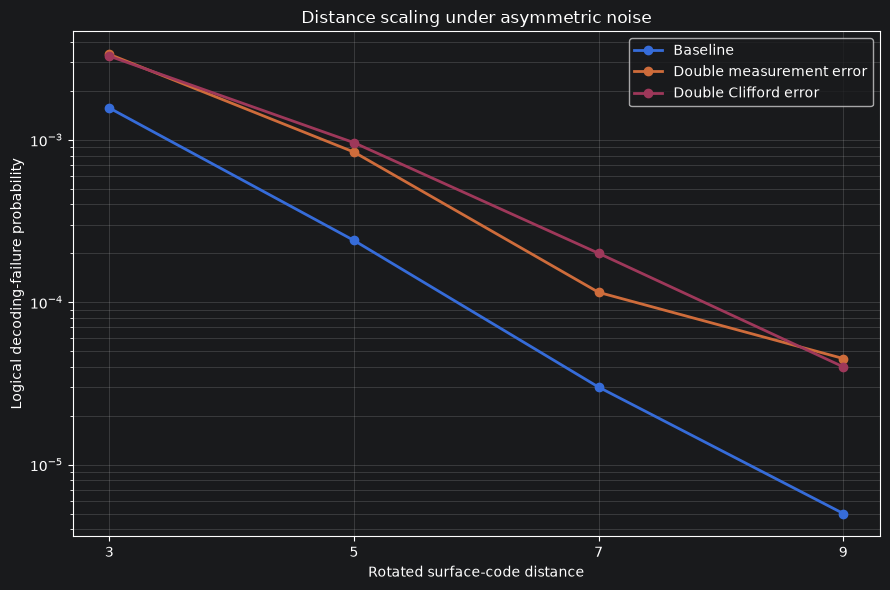

In [33]:
# Create a figure comparing exponential error suppression across code distances under asymmetric noise
figure, axis = plt.subplots(
    figsize=(9, 6)
)

# Plot logical failure rate (with Rule-of-Three floor for zero-failure runs) vs. code distance
for model_name in (
    DISTANCE_COMPARISON_MODELS
):
    subset = distance_sensitivity_df[
        distance_sensitivity_df[
            "noise_model_name"
        ] == model_name
    ].sort_values(
        "distance"
    )

    axis.plot(
        subset["distance"],
        subset[
            "logical_rate_for_plot"
        ],
        marker="o",
        linewidth=2,
        label=model_name,
    )

# Use a logarithmic y-axis so exponential error suppression appears as a straight downward slope
axis.set_yscale("log")

# Configure axis labels, plot title, discrete odd-distance x-ticks, gridlines, and legend
axis.set_xlabel(
    "Rotated surface-code distance"
)

axis.set_ylabel(
    "Logical decoding-failure probability"
)

axis.set_title(
    "Distance scaling under asymmetric noise"
)

axis.set_xticks(
    DISTANCE_COMPARISON_VALUES
)

axis.grid(
    True,
    which="both",
    alpha=0.3,
)

axis.legend()

# Adjust padding, export high-resolution PNG to disk, and display inline
figure.tight_layout()

distance_sensitivity_path = (
    FIGURE_DIR
    / "asymmetric_noise_distance_scaling.png"
)

figure.savefig(
    distance_sensitivity_path,
    dpi=200,
    bbox_inches="tight",
)

plt.show()

In [34]:
# Save the results
# Export full one-at-a-time parameter sweep results to CSV
sensitivity_results_path = (
    RESULTS_DIR
    / "asymmetric_noise_sensitivity.csv"
)

sensitivity_df.to_csv(
    sensitivity_results_path,
    index=False,
)

# Export ranked local logarithmic sensitivity (elasticity) metrics to CSV
local_sensitivity_path = (
    RESULTS_DIR
    / "asymmetric_noise_local_sensitivity.csv"
)

local_sensitivity_df.to_csv(
    local_sensitivity_path,
    index=False,
)

# Export multi-distance error suppression results across noise profiles to CSV
distance_sensitivity_results_path = (
    RESULTS_DIR
    / "asymmetric_noise_distance_scaling.csv"
)

distance_sensitivity_df.to_csv(
    distance_sensitivity_results_path,
    index=False,
)

# Wrap the single baseline dictionary in a one-row DataFrame and export to CSV
baseline_result_path = (
    RESULTS_DIR
    / "asymmetric_noise_baseline.csv"
)

pd.DataFrame(
    [baseline_result]
).to_csv(
    baseline_result_path,
    index=False,
)

# Confirm output file paths in notebook logs
print(
    f"Saved sensitivity sweep to: "
    f"{sensitivity_results_path}"
)

print(
    f"Saved sensitivity ranking to: "
    f"{local_sensitivity_path}"
)

print(
    f"Saved distance comparison to: "
    f"{distance_sensitivity_results_path}"
)

Saved sensitivity sweep to: C:\Users\Karthi\Qauntum\results\asymmetric_noise_sensitivity.csv
Saved sensitivity ranking to: C:\Users\Karthi\Qauntum\results\asymmetric_noise_local_sensitivity.csv
Saved distance comparison to: C:\Users\Karthi\Qauntum\results\asymmetric_noise_distance_scaling.csv


# Asymmetric-Noise Results

The one-factor-at-a-time experiment separated the effects of Clifford-gate depolarisation ($p_{\text{clifford}}$), data-qubit depolarisation ($p_{\text{data}}$), measurement flips ($p_{\text{meas}}$), and reset flips ($p_{\text{reset}}$). Each parameter was varied independently while holding the remaining error rates fixed at their baseline values.

### Key Findings

* **Unequal Logical Sensitivity:** The logical failure probability ($P_L$) did not respond equally to the same proportional change ($\alpha = p_i / p_{i,\text{base}}$) in each error source. This difference arises because the rotated surface-code circuit contains different multiplicities of each operation and because faults at distinct circuit locations propagate into different detector and logical-error patterns.
* **Syndrome Traffic vs. Logical Risk:** The mean detection-event count ($\langle N_{\text{det}} \rangle$) increased as physical noise was raised. However, a larger increase in detector activity did not automatically imply the largest increase in $P_L$; isolated faults are readily detectable and correctable, whereas specific combinations form uncorrectable logical error chains of weight $\ge (d + 1)/2$.
* **Local Logarithmic Sensitivity:** The elasticity analysis ranked the error mechanisms by the proportional response of the logical failure probability near the chosen baseline:
  $$S_i = \frac{\partial \ln P_L}{\partial \ln p_i} \approx \frac{\ln\!\left(P_L(2p_{i,\text{base}}) / P_L(0.5p_{i,\text{base}})\right)}{\ln 4}$$
  This ranking is specific to the generated circuit, baseline error values, code distance ($d$), number of syndrome rounds ($r = d$), and the PyMatching MWPM decoder.
* **Code-Distance Scaling:** The distance comparison ($d \in \{3, 5, 7, 9\}$) showed whether increasing code distance continued to exponentially suppress logical errors ($P_L \propto (p / p_{\text{th}})^{(d+1)/2}$) under the modified noise models. Doubling a single error source reduced the suppression benefit provided by larger codes even when the remaining physical error rates were unchanged.

### Methodological Limitations

* **One-Factor-at-a-Time Scope:** Because parameters were varied individually, the experiment did not capture higher-order interactions between error sources (for example, joint measurement and reset errors combining differently from either mechanism in isolation). A full factorial or variance-based sensitivity study (such as Sobol indices) would be required to quantify cross-channel interactions.
* **Stochastic Pauli Approximation:** The noise model remained stochastic and Pauli-based. It did not include leakage, coherent calibration errors, crosstalk, temporally correlated noise, or spatially correlated faults, all of which can violate the error-independence assumptions used by both the circuit model and the matching decoder.

### Implications for Quantum–Classical Co-Design

Decoder bandwidth and hardware architecture requirements depend on the complete physical error profile $\{p_{\text{clifford}}, p_{\text{data}}, p_{\text{meas}}, p_{\text{reset}}\}$ rather than a single aggregate physical error rate. Optimising only an average error rate can conceal which operations generate the dominant detector traffic and logical failure risk.
